# Workshop 2 — Exploring the Silver Layer with Pandas
**Team 4 · Tropical Cyclone Monitoring · Data Analysis Programming 2026-II**

This notebook reads the Parquet files produced by the `silver_processing` DAG in `datalake_silver/`
(`tropical_cyclones_YYYYMMDD_HHMMSS.parquet`) and shows their schema, lineage, content and quality flags.

**How to run** (no Python needed on the host — it runs inside the Airflow container):
```bash
docker compose exec airflow-scheduler jupyter nbconvert --to notebook --execute --inplace /opt/airflow/notebooks/02_silver_exploration.ipynb
```
It also runs locally with `pip install pandas pyarrow matplotlib jupyter` from the repository root.

In [1]:
import json
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT
SILVER = ROOT / "datalake_silver"
files = sorted(SILVER.glob("tropical_cyclones_*.parquet"))
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
print(f"{len(files)} Silver files in {SILVER}")
pd.DataFrame([{"file": f.name, "size_KB": round(f.stat().st_size / 1024, 1),
               "rows": pq.ParquetFile(f).metadata.num_rows} for f in files])

2 Silver files in /opt/airflow/datalake_silver


,file,size_KB,rows
0,tropical_cyclones_20261117_014500.parquet,44.2,147
1,tropical_cyclones_20261117_020252.parquet,18.9,0


## 1. Schema of a Silver file
The schema is enforced with an explicit pyarrow schema; categorical fields are dictionary-encoded and come back as `category` in Pandas.

In [2]:
first = next(f for f in files if pq.ParquetFile(f).metadata.num_rows > 0)
print(first.name)
print(pq.read_schema(first).to_string(show_schema_metadata=False))

tropical_cyclones_20261117_014500.parquet
event_id: string not null
source: dictionary<values=string, indices=int32, ordered=0> not null
event_type: dictionary<values=string, indices=int32, ordered=0> not null
storm_id: string not null
storm_name: string
storm_name_raw: string
is_unnamed: bool not null
basin: dictionary<values=string, indices=int32, ordered=0> not null
timestamp_utc: timestamp[us, tz=UTC] not null
latitude: double not null
longitude: double not null
wind_kt: double
wind_avg_period: dictionary<values=string, indices=int32, ordered=0> not null
sshs_category: int8
pressure_hpa: double
peak_wind_kt: double
nature: dictionary<values=string, indices=int32, ordered=0>
track_type: dictionary<values=string, indices=int32, ordered=0>
is_provisional: bool not null
is_spur: bool not null
storm_speed_kt: double
storm_dir_deg: double
motion_derived: bool not null
dist2land_km: double
alert_level: dictionary<values=string, indices=int32, ordered=0>
alert_score: double
is_current: boo

## 2. Lineage: which Bronze files produced each Silver file
Each file carries a `tcmon_lineage` metadata entry, and every row has `bronze_file` and `bronze_sha256` columns.

In [3]:
lineage = [json.loads(pq.read_schema(f).metadata[b"tcmon_lineage"]) for f in files]
pd.DataFrame([{"silver_file": l["silver_file"], "bronze_files": ", ".join(l["bronze_files"]), "rows": l["rows"],
               "rejected": l["rejected"], **{f"dedup_{k}": v for k, v in l["dedup"].items()}} for l in lineage])

,silver_file,bronze_files,rows,rejected,dedup_input,dedup_within_batch_duplicates,dedup_cross_batch_duplicates,dedup_revisions,dedup_output
0,tropical_cyclones_20261117_014500.parquet,"gdacs_tc_20261117_010000.json, ibtracs_active_...",147,0,147,0,0,0,147
1,tropical_cyclones_20261117_020252.parquet,"gdacs_tc_20261117_020244.json, ibtracs_active_...",0,0,147,0,147,0,0


## 3. Read all Silver files with Pandas

In [4]:
df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
print(df.shape)
print(df.dtypes.to_string())
df.head(10)

(147, 38)
event_id                     string[python]
source                             category
event_type                         category
storm_id                     string[python]
storm_name                   string[python]
storm_name_raw               string[python]
is_unnamed                          boolean
basin                              category
timestamp_utc           datetime64[us, UTC]
latitude                            float64
longitude                           float64
wind_kt                             float64
wind_avg_period                    category
sshs_category                          Int8
pressure_hpa                        float64
peak_wind_kt                        float64
nature                             category
track_type                         category
is_provisional                      boolean
is_spur                             boolean
storm_speed_kt                      float64
storm_dir_deg                       float64
motion_derived        

/tmp/ipykernel_794/2514403283.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
/tmp/ipykernel_794/2514403283.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
/tmp/ipykernel_794/2514403283.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or a

,event_id,source,event_type,storm_id,storm_name,storm_name_raw,is_unnamed,basin,timestamp_utc,latitude,longitude,wind_kt,wind_avg_period,sshs_category,pressure_hpa,peak_wind_kt,nature,track_type,is_provisional,is_spur,storm_speed_kt,storm_dir_deg,motion_derived,dist2land_km,alert_level,alert_score,is_current,gdacs_episode_id,date_modified_utc,wind_iqr_outlier,speed_zscore_outlier,qc_flags,record_hash,is_revision,bronze_file,bronze_sha256,silver_run_ts,processed_at_utc
0,00b125dfef41d29c1d14a46711c2e5217e66f1ea,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-08 12:00:00+00:00,11.6,-155.6,40.0,1-min,0,1002.0,NaN,TS,PROVISIONAL,True,False,11.0,275.0,False,817.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,8c4be459c1b0ec959185f6cf0a31bbeb49c97888a81827...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
1,021d5867fc07504cb217d4389a02e493c22fddba,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-11 21:00:00+00:00,9.8,-169.3,40.0,1-min,0,1002.0,NaN,TS,PROVISIONAL,True,False,12.0,265.0,False,1700.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,7c828a8c6093fba19b04a1aa5ece93bc0019015ec25108...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
2,027e77475a9f397e96c399f77ec9ecbb2eae9d6c,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-02 21:00:00+00:00,7.8,-131.5,20.0,1-min,-1,NaN,NaN,DS,PROVISIONAL,True,False,13.0,275.0,False,2796.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,649a0aa1bafb40a003a91a11ade51d5660af5adf67cd22...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
3,028d1af6d65420841e3a0a8b0395a2caab7cacbe,ibtracs_active,tc_track_fix,2026312S13053,<NA>,UNNAMED,True,SI,2026-11-08 03:00:00+00:00,-13.2,51.6,37.0,1-min,0,1007.0,NaN,NR,PROVISIONAL,True,False,7.0,305.0,False,174.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,ccc1a34b5eb6ee8ae277874112fb0fa04991cc7f019f72...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
4,05fe0d5f3d4fa899d5968241d9bb3825d678965c,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-11 00:00:00+00:00,10.5,-165.6,40.0,1-min,0,1002.0,NaN,TS,PROVISIONAL,True,False,7.0,245.0,False,1418.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,8439aeb791567d74c14aa964abb7636c83e86ee5232ba2...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
5,06cc0a09d2045340488370e4883f4058e97898c3,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-07 03:00:00+00:00,11.5,-151.3,43.0,1-min,0,1001.0,NaN,TS,PROVISIONAL,True,False,11.0,275.0,False,978.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,e2503e6a2bdd03d3d0e427263be9deea688f10e73a0c5c...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
6,080c35625b25d9593cf1c3e684f2315050bf5f0c,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-12 03:00:00+00:00,9.7,-170.5,35.0,1-min,0,1004.0,NaN,TS,PROVISIONAL,True,False,13.0,270.0,False,1779.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,a3c981c324ada71558fb041c39b2b8aea84cc2eefed75c...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
7,0a34747775edb9fe5ca81b10b9c52ec7be55298d,ibtracs_active,tc_track_fix,2026307N08230,PENA,PENA,False,EP,2026-11-11 03:00:00+00:00,10.3,-165.9,40.0,1-min,0,1002.0,NaN,TS,PROVISIONAL,True,False,7.0,250.0,False,1450.0,NaN,NaN,<NA>,<NA>,NaT,False,False,,438e1828899c676f6c62a16dda283df11c4ac2f7151ec8...,False,ibtracs_active_20261117_010000.json,3425a0ee46519543f1db8d8522ba7d9a48a05409c471f8...,20261117_014500,2026-11-17 02:05:04.014869+00:00
8

## 4. Content by source and storm

In [5]:
(df.groupby(["source", "storm_id", "storm_name", "basin"], dropna=False, observed=True)
   .agg(rows=("event_id", "size"), first=("timestamp_utc", "min"), last=("timestamp_utc", "max"),
        max_wind_kt=("wind_kt", "max"), peak_wind_kt=("peak_wind_kt", "max"))
   .reset_index())

,source,storm_id,storm_name,basin,rows,first,last,max_wind_kt,peak_wind_kt
0,gdacs_tc,1001347,CEMPAKA,UN,1,2026-11-11 12:00:00+00:00,2026-11-11 12:00:00+00:00,NaN,94.991793
1,gdacs_tc,1001348,PENA,UN,1,2026-11-12 15:00:00+00:00,2026-11-12 15:00:00+00:00,NaN,49.995680
2,gdacs_tc,1001350,XAVIER,UN,1,2026-11-16 18:00:00+00:00,2026-11-16 18:00:00+00:00,NaN,119.989633
3,gdacs_tc,1001351,AKVAN,UN,1,2026-11-16 18:00:00+00:00,2026-11-16 18:00:00+00:00,NaN,49.995680
4,ibtracs_active,2026307N08230,PENA,EP,81,2026-11-02 12:00:00+00:00,2026-11-12 12:00:00+00:00,50.0,NaN
5,ibtracs_active,2026310N18149,CEMPAKA,WP,43,2026-11-06 06:00:00+00:00,2026-11-11 12:00:00+00:00,93.0,NaN
6,ibtracs_active,2026312S13053,<NA>,SI,19,2026-11-07 18:00:00+00:00,2026-11-10 00:00:00+00:00,39.0,NaN


## 5. Missing values and quality flags

In [6]:
nulls = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
display(nulls[nulls > 0].to_frame("null_%"))
display(df[["is_unnamed", "is_provisional", "is_spur", "motion_derived", "wind_iqr_outlier",
            "speed_zscore_outlier", "is_revision"]].sum().to_frame("rows_flagged"))
df["qc_flags"].replace("", "(none)").value_counts()

,null_%
date_modified_utc,97.3
alert_score,97.3
is_current,97.3
gdacs_episode_id,97.3
peak_wind_kt,97.3
alert_level,97.3
storm_name,12.9
pressure_hpa,6.8
sshs_category,2.7
storm_dir_deg,2.7


,rows_flagged
is_unnamed,19
is_provisional,143
is_spur,0
motion_derived,0
wind_iqr_outlier,16
speed_zscore_outlier,4
is_revision,0


qc_flags
(none)    147
Name: count, dtype: Int64

## 6. Tracks and intensity

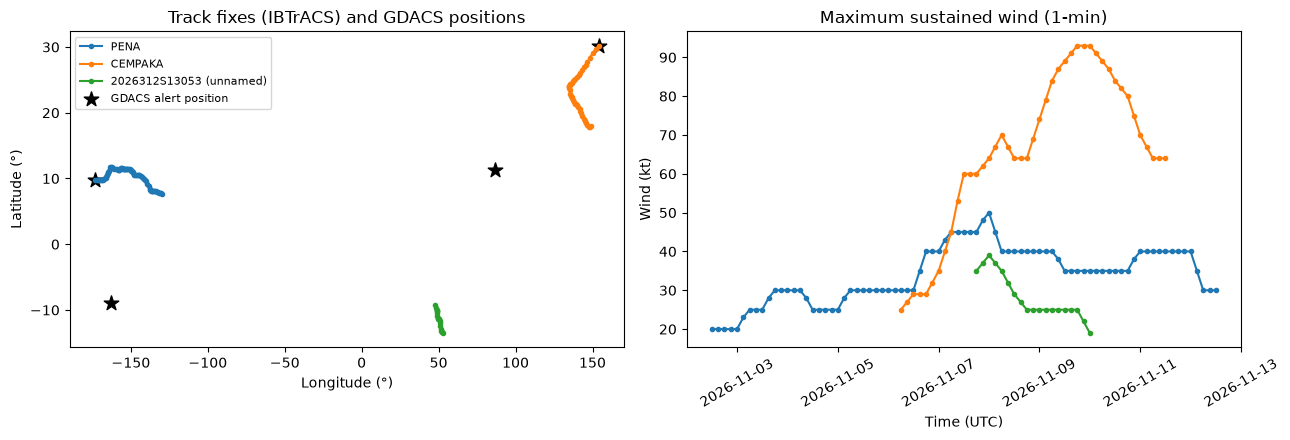

In [7]:
fixes = df[df.event_type == "tc_track_fix"].sort_values("timestamp_utc")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for (sid, name), g in fixes.groupby(["storm_id", "storm_name"], dropna=False, observed=True):
    label = name if isinstance(name, str) else f"{sid} (unnamed)"
    ax[0].plot(g.longitude, g.latitude, marker=".", label=label)
    ax[1].plot(g.timestamp_utc, g.wind_kt, marker=".", label=label)
alerts = df[df.event_type == "tc_alert_episode"]
ax[0].scatter(alerts.longitude, alerts.latitude, marker="*", s=120, c="k", label="GDACS alert position")
ax[0].set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="Track fixes (IBTrACS) and GDACS positions")
ax[1].set(xlabel="Time (UTC)", ylabel="Wind (kt)", title="Maximum sustained wind (1-min)")
ax[0].legend(fontsize=8); ax[1].tick_params(axis="x", rotation=30); plt.tight_layout(); plt.show()

## 7. Rejected records (quarantine)

In [8]:
rej = sorted((SILVER / "_rejected").glob("*.json"))
print(f"{len(rej)} rejected-record files", [p.name for p in rej])

0 rejected-record files []
